In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("fernando2rad/brain-tumor-mri-images-30-classes")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-images-30-classes' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-images-30-classes


In [ ]:
pip install pydicom

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as f
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import WeightedRandomSampler , DataLoader, random_split
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pydicom
import os
from collections import Counter


transform = transforms.Compose([transforms.Resize((224, 224)),
                                transforms.ToTensor() , transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                           std=[0.229, 0.224, 0.225]) ])

In [ ]:
data_dir = "/kaggle/input/brain-tumor-mri-images-30-classes"
dataset = datasets.ImageFolder(data_dir, transform=transform)

train_size = int((len(dataset) * 0.8))
test_size = int(len(dataset)) - train_size
train_set, test_set = random_split(dataset, [train_size, test_size])

train_loader = DataLoader( train_set, batch_size = 32, shuffle = True , num_workers = 2)
test_loader = DataLoader(test_set, batch_size = 32, shuffle = False, num_workers= 2)

#Image optimization functions
#### Clahe_optim : a function that applies a CLAHE filter , for fixing contrast discrepancies between different images

In [ ]:

def Clahe_optim(image_path):

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    img_clahe = clahe.apply(img)

    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    axs[0, 0].imshow(img, cmap='gray')
    axs[0, 0].set_title('Original MRI')

    axs[0, 1].hist(img.ravel(), 128, [0,128])
    axs[0, 1].set_title('Original histogram')

    axs[1, 0].imshow(img_clahe, cmap='gray')
    axs[1, 0].set_title('MRI after CLAHE ')

    axs[1, 1].hist(img_clahe.ravel(), 128, [0,128])
    axs[1, 1].set_title('CLAHE Histogram')

    plt.tight_layout()
    plt.show()

    return img_clahe


/tmp/ipykernel_2216/1389404041.py:13: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[0, 1].hist(img.ravel(), 128, [0,128])
/tmp/ipykernel_2216/1389404041.py:19: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axs[1, 1].hist(img_clahe.ravel(), 128, [0,128])


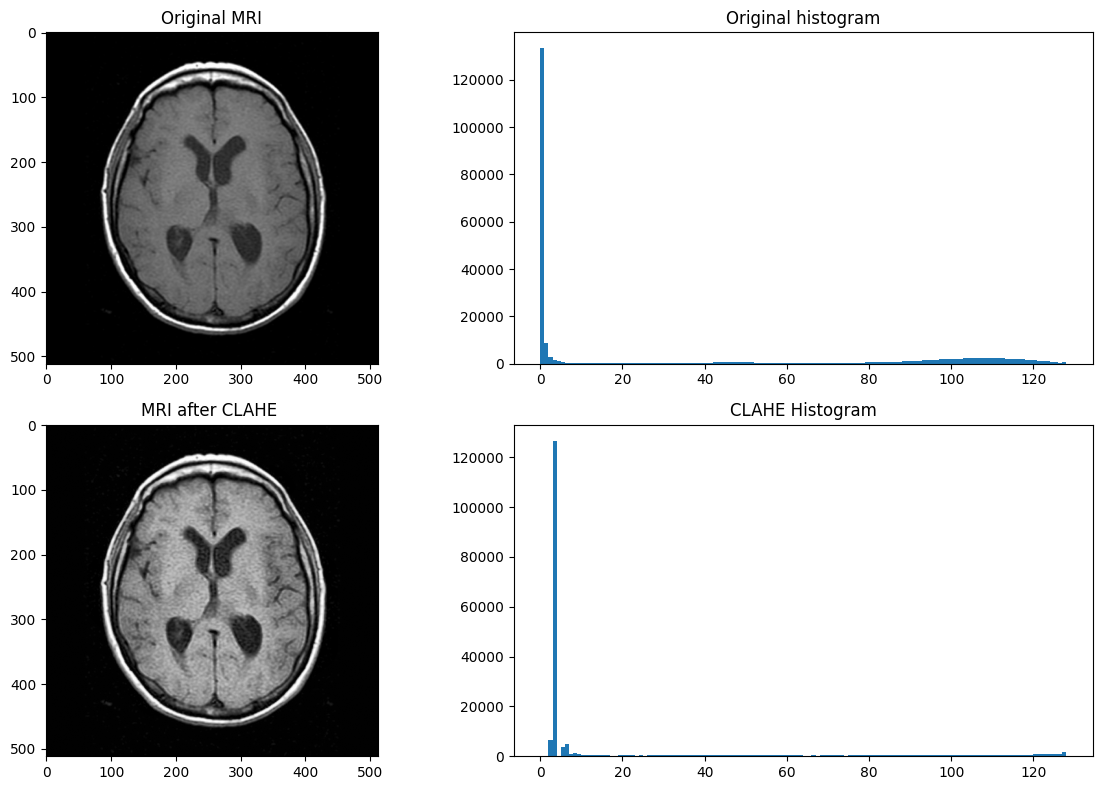

In [ ]:
img = Clahe_optim('/kaggle/input/brain-tumor-mri-images-30-classes/Astrocytoma T1/T1 - Anaplastic astrocytoma (pineal region) 001.jpg')


In [ ]:
def crop_contour(img_path):
  img = cv.imread(img_path)
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


  _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)

  contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

  if contours:

      c = max(contours, key=cv2.contourArea)


      x, y, w, h = cv2.boundingRect(c)


      cropped_img = img[y:y+h, x:x+w]

      plt.figure(figsize=(8, 4))
      plt.subplot(1, 2, 1)
      plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
      plt.title('Original image')

      plt.subplot(1, 2, 2)
      plt.imshow(cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB))
      plt.title('Cropped image')
      plt.show()

      return cropped_img
  else:
      print("No contour detected")
      return img

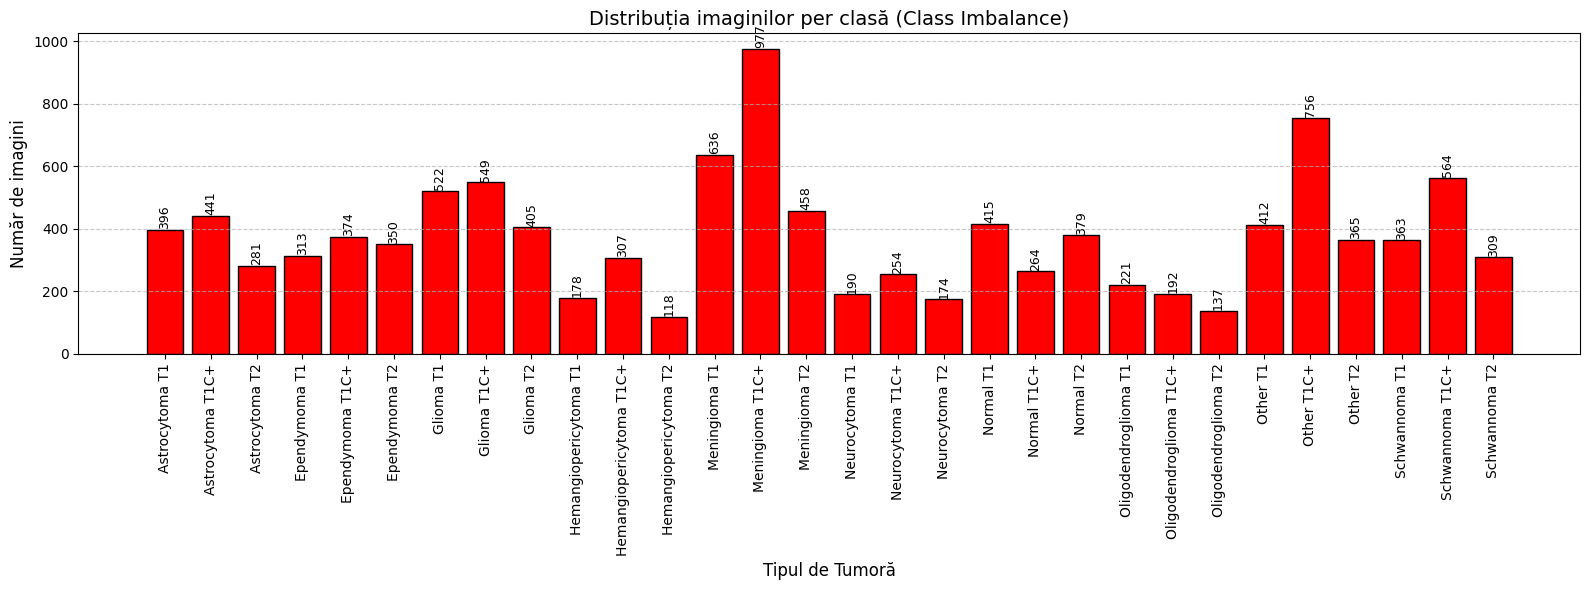

In [ ]:
import os
import matplotlib.pyplot as plt

dataset_path = "/kaggle/input/brain-tumor-mri-images-30-classes"

class_names = []
class_counts = []

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_path):
        num_images = len([f for f in os.listdir(class_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        class_names.append(class_name)
        class_counts.append(num_images)


plt.figure(figsize=(16, 6)) # Un grafic mai lat pentru 30 de clase
plt.bar(class_names, class_counts, color='red', edgecolor='black')
plt.xticks(rotation=90)
plt.xlabel("Tipul de Tumoră", fontsize=12)
plt.ylabel("Număr de imagini", fontsize=12)
plt.title("Distribuția imaginilor per clasă ", fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)


for i, count in enumerate(class_counts):
    plt.text(i, count + 2, str(count), ha='center', va='bottom', rotation=90, fontsize=9)

plt.tight_layout()
plt.show()